In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Cell 1 — Imports and configuration
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
FS = 200
SUBJECTS = ["SA01", "SA02", "SA03", "SA04"]
DATASET_PATH = Path("/content/drive/MyDrive/sisdataset")
OUTPUT_DIR = Path("/content/drive/MyDrive/fall_monitoring_paper_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset path exists:", DATASET_PATH.exists())
print("Output directory:", OUTPUT_DIR)

Dataset path exists: True
Output directory: /content/drive/MyDrive/fall_monitoring_paper_outputs


In [ ]:
# Cell 2 — Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

assert DATASET_PATH.exists(), (
    f"Dataset folder not found: {DATASET_PATH}. "
    "Update DATASET_PATH to your SisFall folder."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Cell 3 — Load SisFall recordings
def load_sisfall(file_path):
    data = pd.read_csv(
        file_path, header=None, sep=",",
        skipinitialspace=True, dtype=str
    )
    data = data.apply(
        lambda col: pd.to_numeric(
            col.str.strip().str.rstrip(";"), errors="raise"
        )
    )
    if data.shape[1] != 9:
        raise ValueError(
            f"Expected 9 sensor columns but found {data.shape[1]} in {file_path}"
        )
    if data.empty or not np.isfinite(data.to_numpy(dtype=float)).all():
        raise ValueError(f"Empty or non-finite recording: {file_path}")
    return data.to_numpy(dtype=float)

def recording_label(filename):
    prefix = Path(filename).stem.split("_")[0]
    if prefix.startswith("F"):
        return 1
    if prefix.startswith("D"):
        return 0
    raise ValueError(f"Unrecognized activity label in filename: {filename}")

all_files = []
for subject in SUBJECTS:
    subject_dir = DATASET_PATH / subject
    if not subject_dir.exists():
        raise FileNotFoundError(f"Missing subject directory: {subject_dir}")
    all_files.extend(sorted(subject_dir.glob("*.txt")))

print("Subjects:", SUBJECTS)
print("Total TXT files found:", len(all_files))
print("Expected based on previous inspection: 616")

Subjects: ['SA01', 'SA02', 'SA03', 'SA04']
Total TXT files found: 616
Expected based on previous inspection: 616


In [ ]:
# Cell 4 — Validate dataset structure and class counts
validation_rows = []
for subject in SUBJECTS:
    files = sorted((DATASET_PATH / subject).glob("*.txt"))
    for path in files:
        raw = load_sisfall(path)
        validation_rows.append({
            "subject": subject,
            "file": path.name,
            "label": recording_label(path.name),
            "samples": len(raw),
            "columns": raw.shape[1],
            "duration_seconds_at_200Hz": len(raw) / FS
        })

dataset_df = pd.DataFrame(validation_rows)
display(dataset_df.groupby(["subject", "label"]).size().unstack(fill_value=0))
print("Recordings:", len(dataset_df))
print("Sensor columns valid:", bool((dataset_df["columns"] == 9).all()))
print("Failed recordings: 0 if this cell completes successfully")

assert len(dataset_df) == 616, (
    f"Expected 616 recordings based on the current dataset copy, got {len(dataset_df)}. "
    "Inspect the subject folders before continuing."
)
assert set(dataset_df["subject"].unique()) == set(SUBJECTS)
assert dataset_df["columns"].eq(9).all()

label,0,1
subject,,
SA01,79,75
SA02,79,75
SA03,79,75
SA04,79,75


Recordings: 616
Sensor columns valid: True
Failed recordings: 0 if this cell completes successfully


In [ ]:
# Cell 5 — Shared 12-feature extractor
# Magnitudes are computed separately for the three sensor groups.
FEATURE_COLUMNS = [
    f"{sensor}_{stat}"
    for sensor in ["adxl_accel", "gyro", "mma_accel"]
    for stat in ["mean", "std", "min", "max"]
]

def extract_features(sampled_raw):
    if len(sampled_raw) == 0:
        raise ValueError("Cannot extract features from an empty sample set.")

    groups = {
        "adxl_accel": sampled_raw[:, 0:3],
        "gyro": sampled_raw[:, 3:6],
        "mma_accel": sampled_raw[:, 6:9],
    }
    features = {}
    for name, sensor in groups.items():
        magnitude = np.sqrt(np.sum(sensor ** 2, axis=1))
        features[f"{name}_mean"] = float(np.mean(magnitude))
        features[f"{name}_std"] = float(np.std(magnitude, ddof=0))
        features[f"{name}_min"] = float(np.min(magnitude))
        features[f"{name}_max"] = float(np.max(magnitude))
    return features

print("Number of features:", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)

Number of features: 12
['adxl_accel_mean', 'adxl_accel_std', 'adxl_accel_min', 'adxl_accel_max', 'gyro_mean', 'gyro_std', 'gyro_min', 'gyro_max', 'mma_accel_mean', 'mma_accel_std', 'mma_accel_min', 'mma_accel_max']


In [ ]:
# Cell 6 — Define the two sampling policies
def fixed_10hz_indices(raw):
    # Original sampling rate is 200 Hz; keep every 20th sample.
    return np.arange(0, len(raw), FS // 10, dtype=int)

def adaptive_indices_v2(
    raw,
    med_enter=1500.0,
    high_enter=4000.0,
    med_hold=0.5,
    high_hold=1.5,
    tau=0.05
):
    # Parameters are kept from the current v2 experiment.
    magnitude = np.sqrt(np.sum(raw[:, :3] ** 2, axis=1))
    low_rate, med_rate, high_rate = 10, 50, 200

    indices = []
    i = 0
    smooth = None
    previous_smooth = None
    previous_time = None
    med_until = -1.0
    high_until = -1.0

    while i < len(magnitude):
        t = i / FS
        value = magnitude[i]

        if smooth is None:
            smooth = value
            change_rate = 0.0
        else:
            dt = t - previous_time
            alpha = 1.0 - np.exp(-dt / tau)
            smooth = alpha * value + (1.0 - alpha) * smooth
            change_rate = abs(smooth - previous_smooth) / dt

        if change_rate >= high_enter:
            high_until = max(high_until, t + high_hold)
        elif change_rate >= med_enter:
            med_until = max(med_until, t + med_hold)

        if t < high_until:
            rate = high_rate
        elif t < med_until:
            rate = med_rate
        else:
            rate = low_rate

        indices.append(i)
        previous_smooth = smooth
        previous_time = t
        i += max(1, round(FS / rate))

    return np.asarray(indices, dtype=int)

print("Fixed 10 Hz and adaptive v2 functions defined.")

Fixed 10 Hz and adaptive v2 functions defined.


In [ ]:
# Cell 7 — Extract features for both policies
# This may take a few minutes. The same feature extractor is used for both.
feature_rows = []
sampling_rows = []

for n, path in enumerate(sorted(all_files), start=1):
    subject = path.parent.name
    label = recording_label(path.name)
    raw = load_sisfall(path)

    policy_indices = {
        "Fixed 10 Hz": fixed_10hz_indices(raw),
        "Adaptive v2": adaptive_indices_v2(raw),
    }

    for policy, indices in policy_indices.items():
        sampled = raw[indices]
        reduction = 100.0 * (1.0 - len(indices) / len(raw))

        row = {
            "subject": subject,
            "file": path.name,
            "activity": Path(path.name).stem.split("_")[0],
            "label": label,
            "policy": policy,
            "sample_count": int(len(indices)),
            "original_count": int(len(raw)),
            "sample_reduction_pct": float(reduction),
        }
        row.update(extract_features(sampled))
        feature_rows.append(row)

        sampling_rows.append({
            "subject": subject,
            "file": path.name,
            "label": label,
            "policy": policy,
            "sample_count": int(len(indices)),
            "original_count": int(len(raw)),
            "sample_reduction_pct": float(reduction),
        })

    if n % 100 == 0:
        print(f"Processed {n}/{len(all_files)} recordings")

features_df = pd.DataFrame(feature_rows)
sampling_df = pd.DataFrame(sampling_rows)

assert len(features_df) == 2 * len(all_files)
assert features_df[FEATURE_COLUMNS].notna().all().all()
assert np.isfinite(features_df[FEATURE_COLUMNS].to_numpy()).all()

print("Feature table:", features_df.shape)
display(features_df.head())

Processed 100/616 recordings
Processed 200/616 recordings
Processed 300/616 recordings
Processed 400/616 recordings
Processed 500/616 recordings
Processed 600/616 recordings
Feature table: (1232, 20)


,subject,file,activity,label,policy,sample_count,original_count,sample_reduction_pct,adxl_accel_mean,adxl_accel_std,adxl_accel_min,adxl_accel_max,gyro_mean,gyro_std,gyro_min,gyro_max,mma_accel_mean,mma_accel_std,mma_accel_min,mma_accel_max
0,SA01,D01_SA01_R01.txt,D01,0,Fixed 10 Hz,1000,19999,94.999750,270.458422,54.121790,169.236521,478.866370,622.750673,238.255611,108.120303,1535.455633,1043.717119,208.116463,619.720098,1809.279138
1,SA01,D01_SA01_R01.txt,D01,0,Adaptive v2,1836,19999,90.819541,269.278587,56.218676,168.101160,500.864253,634.647937,234.236638,55.326305,1540.757606,1038.222769,216.149576,611.052371,1893.514457
2,SA01,D02_SA01_R01.txt,D02,0,Fixed 10 Hz,1000,20000,95.000000,279.306831,98.781810,123.032516,719.469944,926.475924,385.054895,87.761039,2318.352217,1074.153622,376.223965,474.600885,2705.732064
3,SA01,D02_SA01_R01.txt,D02,0,Adaptive v2,17625,20000,11.875000,280.208514,101.475869,113.969294,719.469944,939.824408,376.818780,31.591138,2504.598571,1077.591230,386.379198,430.894419,2705.732064
4,SA01,D03_SA01_R01.txt,D03,0,Fixed 10 Hz,1000,20000,95.000000,318.810441,201.316852,11.661904,826.643212,1494.513619,418.000295,520.295109,3392.021669,1213.722593,792.183987,45.880279,3177.399723


In [ ]:
# Cell 8 — Reproducible leave-one-subject-out evaluation
# For each fold, train on three subjects and test on the held-out subject.
# Each policy gets its own classifier trained on its own policy-derived features.
results_rows = []
oof_rows = []

for policy in ["Fixed 10 Hz", "Adaptive v2"]:
    policy_df = features_df[features_df["policy"] == policy].copy()

    for test_subject in SUBJECTS:
        train = policy_df[policy_df["subject"] != test_subject]
        test = policy_df[policy_df["subject"] == test_subject].copy()

        model = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1
        )
        model.fit(train[FEATURE_COLUMNS], train["label"])
        pred = model.predict(test[FEATURE_COLUMNS])

        test["prediction"] = pred
        oof_rows.append(test)

        results_rows.append({
            "policy": policy,
            "test_subject": test_subject,
            "accuracy": accuracy_score(test["label"], pred),
            "precision": precision_score(test["label"], pred, zero_division=0),
            "fall_recall": recall_score(test["label"], pred, zero_division=0),
            "f1": f1_score(test["label"], pred, zero_division=0),
            "sample_reduction_pct": test["sample_reduction_pct"].mean(),
            "n_test_recordings": len(test),
            "n_test_fall_recordings": int(test["label"].sum()),
        })

results_df = pd.DataFrame(results_rows)
oof_df = pd.concat(oof_rows, ignore_index=True)

metric_cols = ["accuracy", "precision", "fall_recall", "f1", "sample_reduction_pct"]
summary_df = results_df.groupby("policy")[metric_cols].mean().reset_index()

print("Per-subject results:")
display(results_df.round(4))
print("Mean across four held-out subjects:")
display(summary_df.round(4))

Per-subject results:


,policy,test_subject,accuracy,precision,fall_recall,f1,sample_reduction_pct,n_test_recordings,n_test_fall_recordings
0,Fixed 10 Hz,SA01,0.9091,0.9178,0.8933,0.9054,95.0000,154,75
1,Fixed 10 Hz,SA02,0.9091,0.9552,0.8533,0.9014,94.9997,154,75
2,Fixed 10 Hz,SA03,0.8442,0.7865,0.9333,0.8537,94.9999,154,75
3,Fixed 10 Hz,SA04,0.9156,0.8974,0.9333,0.9150,94.9999,154,75
4,Adaptive v2,SA01,0.9221,0.9437,0.8933,0.9178,83.4490,154,75
5,Adaptive v2,SA02,0.9286,0.9706,0.8800,0.9231,83.3601,154,75
6,Adaptive v2,SA03,0.8571,0.8118,0.9200,0.8625,83.0271,154,75
7,Adaptive v2,SA04,0.9156,0.8780,0.9600,0.9172,83.9618,154,75


Mean across four held-out subjects:


,policy,accuracy,precision,fall_recall,f1,sample_reduction_pct
0,Adaptive v2,0.9058,0.9010,0.9133,0.9051,83.4495
1,Fixed 10 Hz,0.8945,0.8892,0.9033,0.8939,94.9999


In [ ]:
# Cell 9 — Verify recording counts, labels, and predictions
print("Out-of-fold predictions:", len(oof_df))
print("Predictions per policy:")
display(oof_df.groupby("policy").size())
print("Class counts per policy:")
display(oof_df.groupby(["policy", "label"]).size().unstack(fill_value=0))

assert len(oof_df) == 2 * len(dataset_df)
assert oof_df.groupby("policy").size().eq(len(dataset_df)).all()
assert oof_df["prediction"].isin([0, 1]).all()

# Save numeric results for later paper writing.
results_df.to_csv(OUTPUT_DIR / "per_subject_results.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "mean_results.csv", index=False)
oof_df.to_csv(OUTPUT_DIR / "out_of_fold_predictions.csv", index=False)
sampling_df.to_csv(OUTPUT_DIR / "sampling_statistics_per_recording.csv", index=False)

print("CSV results saved to:", OUTPUT_DIR)

Out-of-fold predictions: 1232
Predictions per policy:


,0
policy,
Adaptive v2,616
Fixed 10 Hz,616


Class counts per policy:


label,0,1
policy,,
Adaptive v2,316,300
Fixed 10 Hz,316,300


CSV results saved to: /content/drive/MyDrive/fall_monitoring_paper_outputs


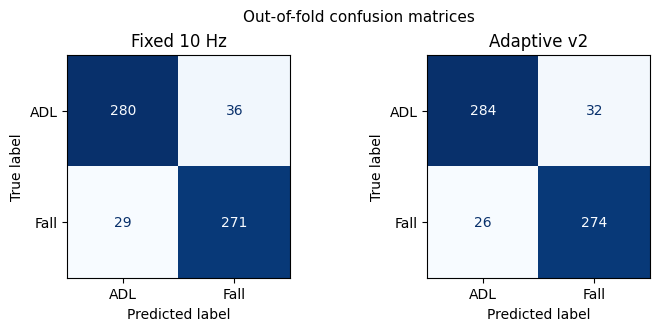

In [ ]:
# Cell 10 — Confusion matrices: combined figure for the paper
# Counts use out-of-fold predictions from all four held-out-subject folds.
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), constrained_layout=True)

for ax, policy in zip(axes, ["Fixed 10 Hz", "Adaptive v2"]):
    subset = oof_df[oof_df["policy"] == policy]
    cm = confusion_matrix(subset["label"], subset["prediction"], labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["ADL", "Fall"]
    )
    disp.plot(ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.set_title(policy)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle("Out-of-fold confusion matrices", fontsize=11)
fig.savefig(OUTPUT_DIR / "fig1_confusion_matrices.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "fig1_confusion_matrices.pdf", bbox_inches="tight")
plt.show()

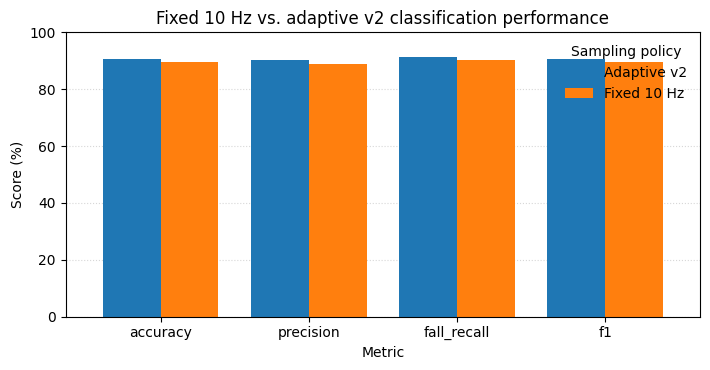

In [ ]:
# Cell 11 — Compare classification metrics
plot_metrics = summary_df.set_index("policy")[["accuracy", "precision", "fall_recall", "f1"]] * 100
ax = plot_metrics.T.plot(kind="bar", figsize=(7.2, 3.8), width=0.78)
ax.set_ylabel("Score (%)")
ax.set_xlabel("Metric")
ax.set_ylim(0, 100)
ax.set_title("Fixed 10 Hz vs. adaptive v2 classification performance")
ax.legend(title="Sampling policy", frameon=False)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.set_axisbelow(True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig2_classification_metrics.png", dpi=300, bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "fig2_classification_metrics.pdf", bbox_inches="tight")
plt.show()

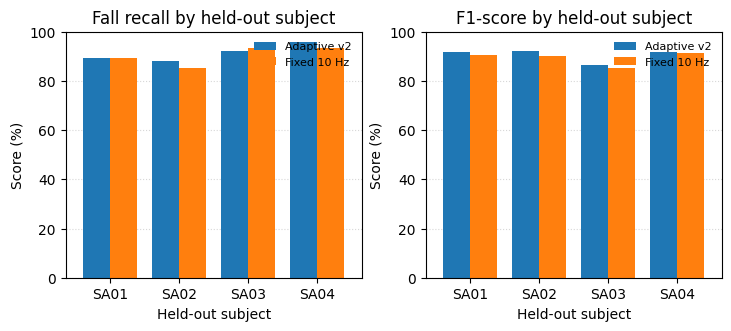

In [ ]:
# Cell 12 — Per-subject fall recall and F1-score
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), constrained_layout=True)

for ax, metric, title in [
    (axes[0], "fall_recall", "Fall recall by held-out subject"),
    (axes[1], "f1", "F1-score by held-out subject")
]:
    pivot = results_df.pivot(index="test_subject", columns="policy", values=metric) * 100
    pivot.plot(kind="bar", ax=ax, width=0.78)
    ax.set_ylabel("Score (%)")
    ax.set_xlabel("Held-out subject")
    ax.set_title(title)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8)

fig.savefig(OUTPUT_DIR / "fig3_subjectwise_performance.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "fig3_subjectwise_performance.pdf", bbox_inches="tight")
plt.show()

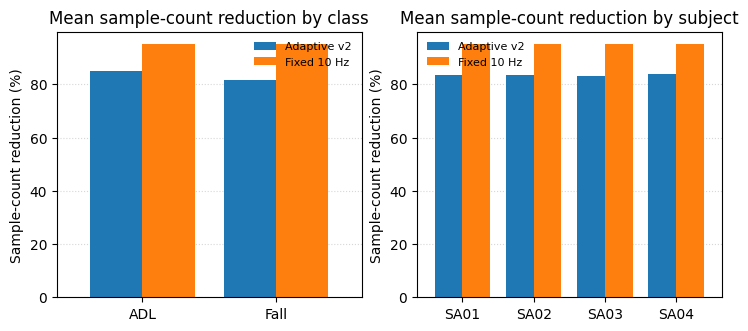

In [ ]:
# Cell 13 — Sample-count reduction by class and subject
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), constrained_layout=True)

class_summary = sampling_df.assign(
    activity_class=sampling_df["label"].map({0: "ADL", 1: "Fall"})
).groupby(["activity_class", "policy"])["sample_reduction_pct"].mean().unstack()
class_summary.plot(kind="bar", ax=axes[0], width=0.78)
axes[0].set_title("Mean sample-count reduction by class")
axes[0].set_ylabel("Sample-count reduction (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(axis="y", linestyle=":", alpha=0.5)
axes[0].set_axisbelow(True)

subject_summary = sampling_df.groupby(["subject", "policy"])["sample_reduction_pct"].mean().unstack()
subject_summary.plot(kind="bar", ax=axes[1], width=0.78)
axes[1].set_title("Mean sample-count reduction by subject")
axes[1].set_ylabel("Sample-count reduction (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(axis="y", linestyle=":", alpha=0.5)
axes[1].set_axisbelow(True)

fig.savefig(OUTPUT_DIR / "fig4_sample_reduction.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "fig4_sample_reduction.pdf", bbox_inches="tight")
plt.show()

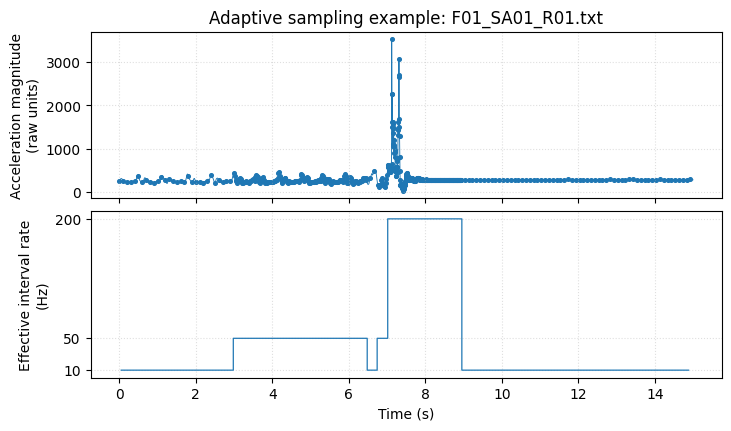

In [ ]:

# Cell 14 — Optional: inspect one recording's adaptive sampling pattern
# This is an explanatory example, not a performance metric.

EXAMPLE_SUBJECT = "SA01"
EXAMPLE_FILE = "F01_SA01_R01.txt"
example_path = DATASET_PATH / EXAMPLE_SUBJECT / EXAMPLE_FILE

if example_path.exists():
    raw = load_sisfall(example_path)
    indices = adaptive_indices_v2(raw)
    times = np.arange(len(raw)) / FS
    selected_times = indices / FS

    # Estimate the effective rate between successive acquired samples.
    interval_rates = 1.0 / np.diff(selected_times)
    interval_midpoints = (selected_times[:-1] + selected_times[1:]) / 2

    fig, axes = plt.subplots(
        2, 1,
        figsize=(7.2, 4.2),
        sharex=True,
        constrained_layout=True
    )

    accel_mag = np.sqrt(np.sum(raw[:, :3] ** 2, axis=1))

    axes[0].plot(times, accel_mag, linewidth=0.65)
    axes[0].scatter(selected_times, accel_mag[indices], s=7)
    axes[0].set_ylabel("Acceleration magnitude\n(raw units)")
    axes[0].set_title(f"Adaptive sampling example: {EXAMPLE_FILE}")
    axes[0].grid(True, linestyle=":", alpha=0.4)

    axes[1].step(
        interval_midpoints,
        interval_rates,
        where="mid",
        linewidth=0.9
    )
    axes[1].set_ylabel("Effective interval rate\n(Hz)")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_yticks([10, 50, 200])
    axes[1].grid(True, linestyle=":", alpha=0.4)

    fig.savefig(
        OUTPUT_DIR / "fig5_adaptive_sampling_example.png",
        dpi=300,
        bbox_inches="tight"
    )
    fig.savefig(
        OUTPUT_DIR / "fig5_adaptive_sampling_example.pdf",
        bbox_inches="tight"
    )

    plt.show()
else:
    print(f"Example recording not found: {example_path}. Update EXAMPLE_FILE if needed.")


In [ ]:

# Cell 15 — Classification reports and final numerical comparison

for policy in ["Fixed 10 Hz", "Adaptive v2"]:
    subset = oof_df[oof_df["policy"] == policy]

    print("\n" + "=" * 60)
    print(policy)
    print("=" * 60)

    print(
        classification_report(
            subset["label"],
            subset["prediction"],
            labels=[0, 1],
            target_names=["ADL", "Fall"],
            digits=4,
            zero_division=0
        )
    )

# Compare mean metrics across the four held-out subjects
comparison = summary_df.set_index("policy")

fixed = comparison.loc["Fixed 10 Hz"]
adaptive = comparison.loc["Adaptive v2"]

print("\n" + "=" * 60)
print("ADAPTIVE V2 MINUS FIXED 10 HZ")
print("=" * 60)

# These metrics are stored as fractions between 0 and 1.
for metric in ["accuracy", "precision", "fall_recall", "f1"]:
    difference = (adaptive[metric] - fixed[metric]) * 100
    print(f"{metric}: {difference:+.2f} percentage points")

# Sample reduction is already stored on a 0–100 percentage scale.
reduction_difference = (
    adaptive["sample_reduction_pct"]
    - fixed["sample_reduction_pct"]
)

print(
    "sample_reduction_pct: "
    f"{reduction_difference:+.2f} percentage points"
)

print("\nMean results across held-out subjects:")
print(
    f"Fixed 10 Hz — Accuracy: {fixed['accuracy'] * 100:.2f}%, "
    f"Precision: {fixed['precision'] * 100:.2f}%, "
    f"Fall Recall: {fixed['fall_recall'] * 100:.2f}%, "
    f"F1: {fixed['f1'] * 100:.2f}%, "
    f"Sample-count reduction: {fixed['sample_reduction_pct']:.2f}%"
)

print(
    f"Adaptive v2 — Accuracy: {adaptive['accuracy'] * 100:.2f}%, "
    f"Precision: {adaptive['precision'] * 100:.2f}%, "
    f"Fall Recall: {adaptive['fall_recall'] * 100:.2f}%, "
    f"F1: {adaptive['f1'] * 100:.2f}%, "
    f"Sample-count reduction: {adaptive['sample_reduction_pct']:.2f}%"
)

print(
    "\nNote: Sample-count reduction is not a direct measurement "
    "of battery-energy savings."
)



Fixed 10 Hz
              precision    recall  f1-score   support

         ADL     0.9061    0.8861    0.8960       316
        Fall     0.8827    0.9033    0.8929       300

    accuracy                         0.8945       616
   macro avg     0.8944    0.8947    0.8945       616
weighted avg     0.8947    0.8945    0.8945       616


Adaptive v2
              precision    recall  f1-score   support

         ADL     0.9161    0.8987    0.9073       316
        Fall     0.8954    0.9133    0.9043       300

    accuracy                         0.9058       616
   macro avg     0.9058    0.9060    0.9058       616
weighted avg     0.9060    0.9058    0.9059       616


ADAPTIVE V2 MINUS FIXED 10 HZ
accuracy: +1.14 percentage points
precision: +1.18 percentage points
fall_recall: +1.00 percentage points
f1: +1.13 percentage points
sample_reduction_pct: -11.55 percentage points

Mean results across held-out subjects:
Fixed 10 Hz — Accuracy: 89.45%, Precision: 88.92%, Fall Recall: 90.3

In [ ]:
# Cell 16 — Export all final tables and run summary
dataset_summary = {
    "dataset_path": str(DATASET_PATH),
    "subjects": SUBJECTS,
    "recordings": int(len(dataset_df)),
    "fall_recordings": int((dataset_df["label"] == 1).sum()),
    "adl_recordings": int((dataset_df["label"] == 0).sum()),
    "original_sampling_rate_hz": FS,
    "policies": ["Fixed 10 Hz", "Adaptive v2"],
    "random_forest": {
        "n_estimators": 300,
        "class_weight": "balanced",
        "random_state": SEED
    },
    "adaptive_v2_parameters": {
        "med_enter": 1500.0,
        "high_enter": 4000.0,
        "med_hold": 0.5,
        "high_hold": 1.5,
        "tau": 0.05,
        "rates_hz": [10, 50, 200]
    },
    "warning": (
        "Sample-count reduction is not measured energy savings; "
        "evaluation is recording-level and currently exploratory."
    )
}
with open(OUTPUT_DIR / "experiment_configuration.json", "w") as f:
    json.dump(dataset_summary, f, indent=2)

print("Completed. Tables, predictions, configuration, and figures saved to:")
print(OUTPUT_DIR)
print("Files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

Completed. Tables, predictions, configuration, and figures saved to:
/content/drive/MyDrive/fall_monitoring_paper_outputs
Files:
 - experiment_configuration.json
 - fig1_confusion_matrices.pdf
 - fig1_confusion_matrices.png
 - fig2_classification_metrics.pdf
 - fig2_classification_metrics.png
 - fig3_subjectwise_performance.pdf
 - fig3_subjectwise_performance.png
 - fig4_sample_reduction.pdf
 - fig4_sample_reduction.png
 - fig5_adaptive_sampling_example.pdf
 - fig5_adaptive_sampling_example.png
 - mean_results.csv
 - out_of_fold_predictions.csv
 - per_subject_results.csv
 - sampling_statistics_per_recording.csv
